# Level 2 · Task 1 — Predicting House Prices with Linear Regression
**Track:** Data Analytics · Level 2  
**Goal:** Build and evaluate a linear regression model that predicts house prices from features such as number of rooms, age, and location-related variables.

**Dataset:** the classic **Boston Housing** dataset (Harrison & Rubinfeld, 1978): 506 census tracts, 13 features, target `MEDV` = median home value in **$1000s** (1970s prices).

| Column | Meaning |
|---|---|
| CRIM | Per-capita crime rate |
| ZN | % of residential land zoned for large lots |
| INDUS | % of non-retail business acres |
| CHAS | 1 if the tract borders the Charles River |
| NOX | Nitric-oxide concentration (air pollution) |
| RM | Average number of rooms per dwelling |
| AGE | % of owner-occupied homes built before 1940 |
| DIS | Weighted distance to five employment centres |
| RAD | Index of accessibility to radial highways |
| TAX | Property-tax rate |
| PTRATIO | Pupil–teacher ratio |
| B | Index derived from the proportion of Black residents (**excluded**, see Section 4) |
| LSTAT | % of lower-status population |
| MEDV | **Target:** median home value ($1000s) |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from warnings import filterwarnings
filterwarnings("ignore")

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

sns.set_style("whitegrid")
RANDOM_STATE = 42

## 1. Load Data & Initial Inspection
The file has **no header row** and is whitespace-separated, so the column names are supplied manually.

In [2]:
columns = ["CRIM", "ZN", "INDUS", "CHAS", "NOX", "RM", "AGE", "DIS", "RAD", "TAX", "PTRATIO", "B", "LSTAT", "MEDV"]
df = pd.read_csv("housing.csv", sep=r"\s+", header=None, names=columns)

print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Houses at the price cap (MEDV = 50):", (df["MEDV"] == 50).sum())
df.head()

Shape: (506, 14)
Missing values: 0
Duplicate rows: 0
Houses at the price cap (MEDV = 50): 16


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2


In [ ]:
df.describe().T.round(2)

### Observations
- **506 rows × 14 columns**, all numeric, with **no missing values and no duplicates**.
- The average median home value is **22.5** ($22.5k in 1970s dollars) and the median is 21.2.
- **16 tracts have `MEDV = 50` exactly.** This is a **price ceiling** in the original survey (values above $50k were recorded as 50), so these prices are censored and will be hard for any model to predict.
- Features are on very different scales (`TAX` up to 711, `NOX` below 1), and `CRIM` is extremely skewed (median 0.26, maximum 89.0).

## 2. Distribution of the Target Variable (Price)

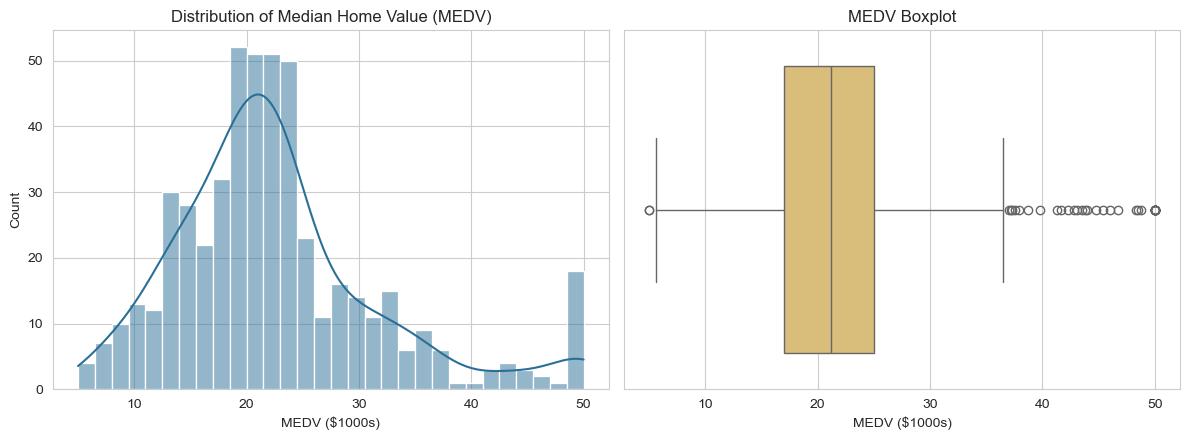

Skewness: 1.11


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(df["MEDV"], bins=30, kde=True, ax=ax[0], color="#2a6f97")
ax[0].set_title("Distribution of Median Home Value (MEDV)"); ax[0].set_xlabel("MEDV ($1000s)")
sns.boxplot(x=df["MEDV"], ax=ax[1], color="#e9c46a")
ax[1].set_title("MEDV Boxplot"); ax[1].set_xlabel("MEDV ($1000s)")
plt.tight_layout(); plt.show()
print("Skewness:", round(df["MEDV"].skew(), 2))

### Observations
- Prices are **right-skewed** (skewness 1.11): most tracts are between $15k and $25k, with a long tail of expensive areas.
- The spike at **50** is the price cap described earlier, visible as a bar on the far right and as outlier dots in the boxplot.
- The skew suggests that a log-transform of the target could help a linear model, which I test in Section 12.

## 3. Feature Selection Discussion
Which features should predict price, and why?

| Feature | Expected effect | Reasoning |
|---|---|---|
| **RM** (rooms) | Positive | More rooms means a larger house, so higher value |
| **LSTAT** (% lower-status residents) | Negative | A proxy for neighbourhood affluence |
| **CRIM** (crime rate) | Negative | Buyers pay less in unsafe areas |
| **NOX** (pollution) | Negative | Air quality affects desirability |
| **PTRATIO** (pupils per teacher) | Negative | Fewer pupils per teacher means better schools |
| **DIS** (distance to employment) | Ambiguous | Closer to jobs raises value, but those areas can be noisier |
| **AGE** (old buildings) | Slightly negative | Older housing stock, though heritage areas can be valuable |
| **CHAS** (river) | Positive | River-front view and amenity |
| **TAX, INDUS, RAD, ZN** | Mixed | Reflect industrial or suburban character |

Correlation with the price confirms the strongest candidates: `LSTAT` (-0.74), `RM` (0.70), `PTRATIO` (-0.51), `INDUS` (-0.48) and `TAX` (-0.47).

### Ethical decision: excluding `B`
The `B` column is calculated from the **proportion of Black residents** in each tract. A model that uses it would be pricing homes partly by neighbourhood racial composition, which encodes historical segregation and discrimination. This is why scikit-learn removed this dataset from its library. I **exclude `B`** from the model. This also does not hurt performance: on my split the test R² is slightly *higher* without it (0.684 vs 0.662).

## 4. Handle Missing Values & Encode Categorical Features

In [4]:
# 1) Missing values: none exist in this dataset
print("Missing values:", df.isnull().sum().sum())

# 2) Drop the ethically problematic column B
data = df.drop(columns="B").copy()

# 3) One-hot encode RAD. It's an accessibility INDEX (1-8 and 24), not a quantity:
#    24 is a code for "beltway access", not 24x more accessible than 1.
print("RAD values:", sorted(data["RAD"].unique()))
data["RAD"] = data["RAD"].astype(int).astype(str)
data = pd.get_dummies(data, columns=["RAD"], drop_first=True, dtype=float)

# CHAS is already a 0/1 dummy variable, so no encoding is needed
print("Final shape:", data.shape)
data.head()

Missing values: 0
RAD values: [1, 2, 3, 4, 5, 6, 7, 8, 24]
Final shape: (506, 20)


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,TAX,PTRATIO,LSTAT,MEDV,RAD_2,RAD_24,RAD_3,RAD_4,RAD_5,RAD_6,RAD_7,RAD_8
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,296.0,15.3,4.98,24.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,242.0,17.8,9.14,21.6,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,242.0,17.8,4.03,34.7,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,222.0,18.7,2.94,33.4,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,222.0,18.7,5.33,36.2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


### Decisions
- **Missing values:** none, so no imputation is needed.
- **One-hot encoding:** `RAD` is a categorical index (the value 24 is a special code for a different kind of access), so I encode it with `drop_first=True` to avoid the dummy-variable trap. Each `RAD_k` coefficient is then relative to RAD = 1.
- `CHAS` is already binary. The remaining features are numeric and used as-is.

## 5. Correlation Heatmap

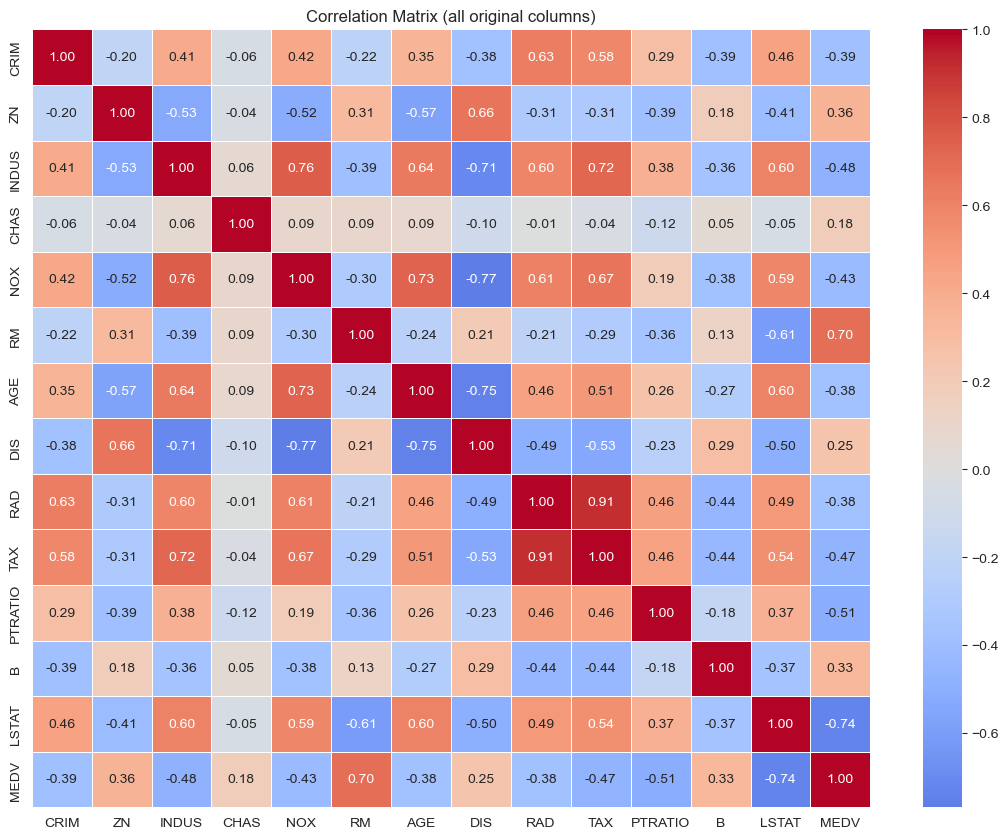

LSTAT     -0.737663
PTRATIO   -0.507787
INDUS     -0.483725
TAX       -0.468536
NOX       -0.427321
CRIM      -0.388305
RAD       -0.381626
AGE       -0.376955
CHAS       0.175260
DIS        0.249929
B          0.333461
ZN         0.360445
RM         0.695360
Name: MEDV, dtype: float64


In [5]:
plt.figure(figsize=(11, 8.5))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=.5)
plt.title("Correlation Matrix (all original columns)")
plt.tight_layout(); plt.show()
print(df.corr()["MEDV"].drop("MEDV").sort_values())

### Observations
- Features most correlated with price: **`RM`** (**+0.70**, more rooms means higher price) and **`LSTAT`** (**-0.74**, the strongest overall). Then `PTRATIO` (-0.51), `INDUS` (-0.48) and `TAX` (-0.47).
- `AGE` (-0.38) has a moderate negative relationship, while `CHAS` (+0.18) is weak.
- **Multicollinearity:** several predictors are strongly correlated with each other, such as `RAD` and `TAX` (+0.91), `NOX` and `INDUS` (+0.76), and `NOX` and `DIS` (-0.77). This can make individual coefficients unstable, so coefficient sizes should be interpreted with care.

## 6. Train/Test Split (80/20)

In [6]:
X = data.drop(columns="MEDV")
y = data["MEDV"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (404, 19)  Test: (102, 19)


## 7. Train a Linear Regression Model

In [7]:
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Model trained. Intercept:", round(model.intercept_, 2))

Model trained. Intercept: 35.66


## 8. Evaluation: MSE, RMSE and R²

In [8]:
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

results = pd.DataFrame({
    "Metric": ["MSE", "RMSE", "R² (test)", "R² (train)"],
    "Value": [mse, rmse, r2, model.score(X_train, y_train)],
}).set_index("Metric")
print(results.round(3))

cv = cross_val_score(LinearRegression(), X, y, cv=KFold(5, shuffle=True, random_state=RANDOM_STATE), scoring="r2")
print("\n5-fold CV R²:", cv.round(3), "| mean:", round(cv.mean(), 3))

             Value
Metric            
MSE         23.179
RMSE         4.814
R² (test)    0.684
R² (train)   0.751

5-fold CV R²: [0.684 0.732 0.724 0.77  0.677] | mean: 0.717


### Observations
| Metric | Value | Meaning |
|---|---|---|
| **MSE** | 23.18 | Mean squared error, in ($1000s)² |
| **RMSE** | 4.81 | Typical prediction error of about **$4,814**, around 21% of the average price |
| **R² (test)** | 0.684 | The model explains **68%** of the price variation on unseen houses |
| R² (train) | 0.751 | Slightly higher than test, so there is only mild overfitting |

The 5-fold cross-validated R² averages **0.717**, ranging from 0.68 to 0.77 across folds. The single 0.684 test score is therefore a reasonable but slightly pessimistic estimate, and results vary by a few points depending on the split.

## 9. Actual vs. Predicted Prices

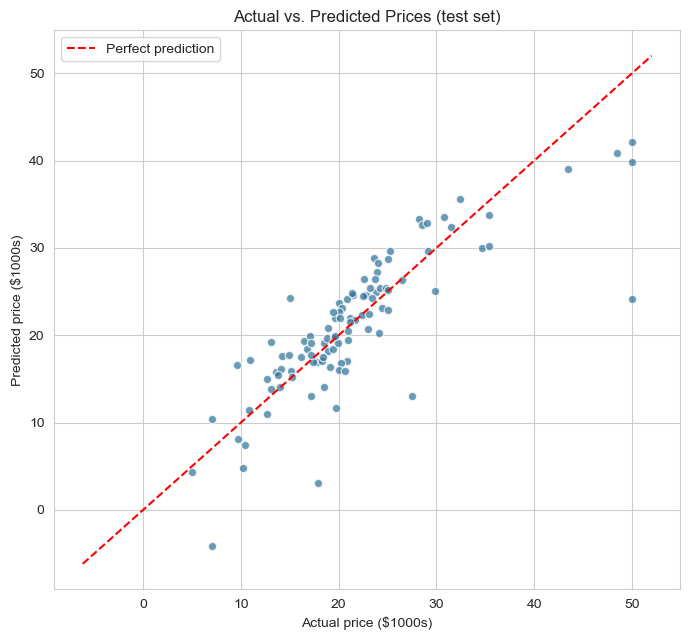

In [9]:
plt.figure(figsize=(7, 6.5))
plt.scatter(y_test, y_pred, alpha=0.7, color="#2a6f97", edgecolor="white")
lims = [min(y_test.min(), y_pred.min()) - 2, max(y_test.max(), y_pred.max()) + 2]
plt.plot(lims, lims, "r--", label="Perfect prediction")
plt.xlabel("Actual price ($1000s)"); plt.ylabel("Predicted price ($1000s)")
plt.title("Actual vs. Predicted Prices (test set)"); plt.legend()
plt.tight_layout(); plt.show()

### Observations
- Points follow the diagonal in the middle of the range, so the model captures the general trend.
- At both **extremes** (tracts predicted below about $15k or above about $35k) the points lie mostly **above the dashed line**, meaning the actual prices are higher than predicted. In the middle of the range the model tracks the line closely.
- The model even predicted **1 negative price** (minimum -4.2), which is impossible. A straight line has no floor, which is a known weakness of linear regression for price data.

## 10. Residual Analysis

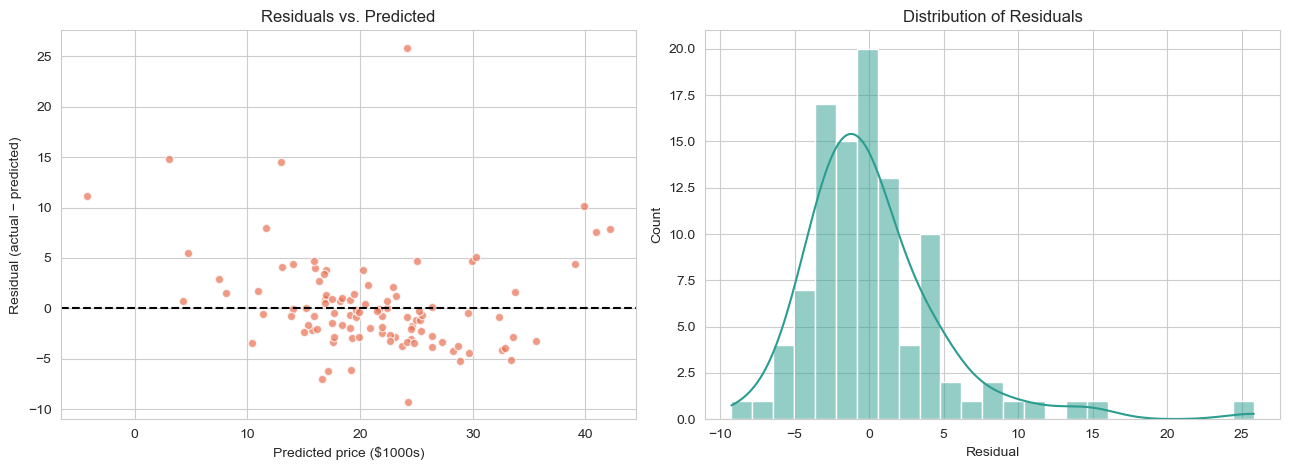

                mean  count
predicted band             
<15             4.31     15
15–25          -0.49     60
25–35          -1.49     22
>35             5.34      5


In [10]:
residuals = y_test - y_pred

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
ax[0].scatter(y_pred, residuals, alpha=0.7, color="#e76f51", edgecolor="white")
ax[0].axhline(0, color="black", linestyle="--")
ax[0].set_xlabel("Predicted price ($1000s)"); ax[0].set_ylabel("Residual (actual − predicted)")
ax[0].set_title("Residuals vs. Predicted")
sns.histplot(residuals, bins=25, kde=True, ax=ax[1], color="#2a9d8f")
ax[1].set_title("Distribution of Residuals"); ax[1].set_xlabel("Residual")
plt.tight_layout(); plt.show()

bands = pd.cut(y_pred, [-100, 15, 25, 35, 100], labels=["<15", "15–25", "25–35", ">35"])
print(pd.DataFrame({"residual": residuals, "predicted band": bands}).groupby("predicted band", observed=True)["residual"].agg(["mean", "count"]).round(2))

### Observations: the residuals are **not** fully random
For a well-fitting linear model the residuals should scatter randomly around zero. Here they do not:
- The overall mean residual is close to zero (0.29), as expected.
- But there is a **systematic U-shaped pattern**. Mean residual by predicted-price band: **<15: +4.3**, 15–25: -0.5, 25–35: -1.5, **>35: +5.3**. The model under-predicts both cheap and expensive tracts and slightly over-predicts the middle.
- This curvature means the **relationship between features and price is not purely linear**. For example, the effect of `LSTAT` flattens at low values and drops sharply at high values.
- The residual distribution has a long **right tail**. The largest error (+25.8) is a capped tract (actual 50) predicted at about 24, and other large errors come from tracts the model priced near zero (for example, predicted 3.1 against an actual 17.9).
- Conclusion: a plain linear model is a reasonable baseline but its assumptions are not fully met. Section 12 tests a log-transform to reduce this.

## 11. Coefficient Analysis

Raw coefficients (effect on price in $1000s per 1-unit change):
NOX       -18.69
DIS        -1.55
PTRATIO    -0.89
LSTAT      -0.54
CRIM       -0.13
TAX        -0.01
AGE        -0.00
ZN          0.04
INDUS       0.04
RAD_6       0.51
RAD_2       1.17
RAD_4       1.87
RAD_5       2.59
CHAS        2.85
RM          4.08
RAD_8       4.16
RAD_7       4.42
RAD_3       4.75
RAD_24      5.41
dtype: float64


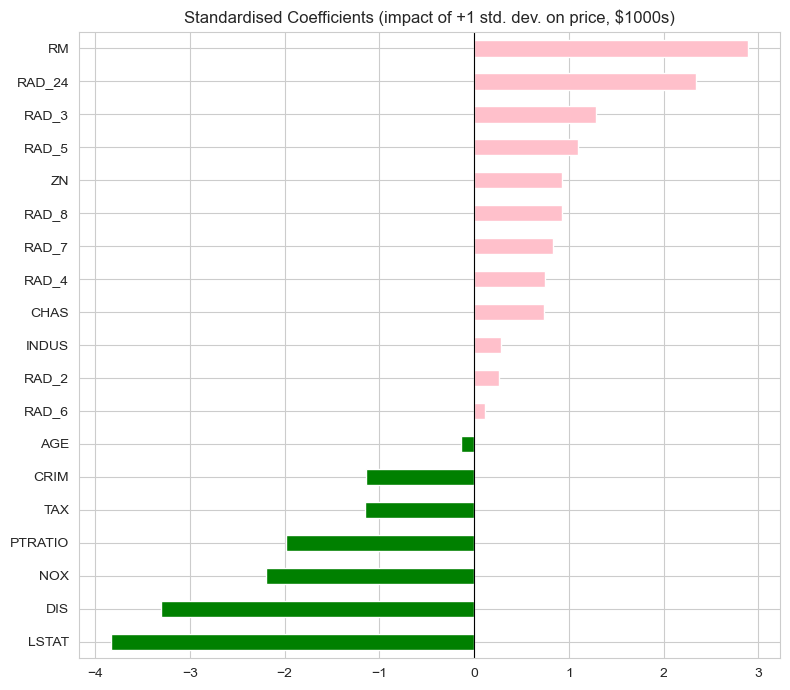

In [15]:
coefs = pd.Series(model.coef_, index=X.columns).sort_values()
print("Raw coefficients (effect on price in $1000s per 1-unit change):")
print(coefs.round(2))

# Standardised coefficients let us compare features on the same scale
scaler = StandardScaler().fit(X_train)
std_coefs = pd.Series(LinearRegression().fit(scaler.transform(X_train), y_train).coef_, index=X.columns).sort_values()

plt.figure(figsize=(8, 7))
colors = ["green" if v < 0 else "pink" for v in std_coefs]
std_coefs.plot(kind="barh", color=colors)
plt.axvline(0, color="black", lw=0.8)
plt.title("Standardised Coefficients (impact of +1 std. dev. on price, $1000s)")
plt.tight_layout(); plt.show()

### Observations
Raw coefficients depend on each feature's units (a one-unit change in `NOX` is huge, while one unit of `TAX` is tiny), so I compare features using **standardised coefficients**.

**Largest negative impact on price**
- **`LSTAT`** (-3.83): the strongest single driver. A one-standard-deviation rise in lower-status population lowers the predicted price by about $3,832.
- **`DIS`** (-3.30), **`NOX`** (-2.20) and **`PTRATIO`** (-1.98).

**Largest positive impact**
- **`RM`** (+2.89): in raw terms, each additional room adds about **$4,080** to the predicted price.
- **`RAD_24`** (+2.34) and the other `RAD_k` dummies, relative to RAD = 1. `CHAS` also raises prices by about $2,855 for river-front tracts.

**Negligible:** `AGE` (-0.13) has essentially no independent effect once the other variables are included, even though it correlates with price on its own (-0.38), because it overlaps with distance, pollution and crime.

> Because of multicollinearity (Section 5), individual coefficients can shift if features are added or removed, so treat them as indicative, not exact causal effects.

## 12. Bonus: Ridge and Lasso Regularisation (and a Log-Price Experiment)

                    R² (test)   RMSE
Linear Regression       0.684  4.814
Ridge                   0.679  4.854
Lasso                   0.684  4.817
Linear (log price)      0.757  4.225

Ridge alpha chosen: 6.251
Lasso alpha chosen: 0.001 | coefficients set to zero: 0


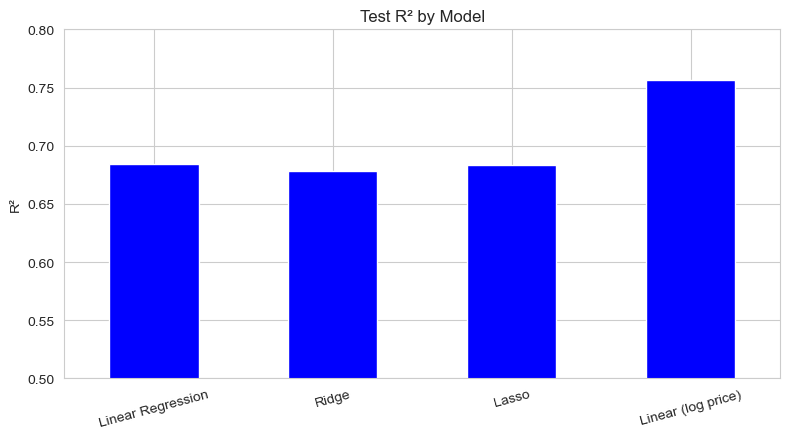

In [13]:
ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 50))).fit(X_train, y_train)
lasso = make_pipeline(StandardScaler(), LassoCV(alphas=np.logspace(-3, 1, 60), cv=5, max_iter=20000)).fit(X_train, y_train)

# Extra: model the LOG of the price, then convert predictions back
log_model = LinearRegression().fit(X_train, np.log(y_train))
log_pred = np.exp(log_model.predict(X_test))

preds = {"Linear Regression": y_pred, "Ridge": ridge.predict(X_test),
         "Lasso": lasso.predict(X_test), "Linear (log price)": log_pred}

comparison = pd.DataFrame({
    name: {"R² (test)": r2_score(y_test, p), "RMSE": np.sqrt(mean_squared_error(y_test, p))}
    for name, p in preds.items()
}).T
print(comparison.round(3))
print("\nRidge alpha chosen:", round(ridge[-1].alpha_, 3))
print("Lasso alpha chosen:", round(lasso[-1].alpha_, 4), "| coefficients set to zero:", int((lasso[-1].coef_ == 0).sum()))

comparison["R² (test)"].plot(kind="bar", figsize=(8, 4.5), color="blue")
plt.title("Test R² by Model"); plt.ylabel("R²"); plt.ylim(0.5, 0.8); plt.xticks(rotation=15)
plt.tight_layout(); plt.show()

| Model | R² (test) | RMSE |
|---|---|---|
| Linear Regression | 0.684 | 4.81 |
| Ridge (α ≈ 6.3) | 0.679 | 4.85 |
| Lasso (α ≈ 0.001) | 0.684 | 4.82 |
| **Linear on log(price)** | **0.757** | **4.23** |

### Observations
- **Regularisation does not help here.** Ridge and Lasso score the same as plain linear regression, and Lasso kept all features (its chosen α is tiny). With about 400 training rows and only 18 features, the model is not overfitting much (train R² 0.75 vs test 0.68), so penalising coefficients has nothing to fix.
- **The bottleneck is the model form, not the variance.** Taking the log of the price, which reduces the right skew and the curved residuals, improves R² from 0.684 to **0.757** and lowers RMSE from 4.81 to 4.23. It also guarantees positive predictions.
- This confirms the residual analysis: the main weakness is non-linearity, which regularisation cannot fix.

## 13. Conclusion

**Model performance:** Linear regression explains about **68%** of the price variation on unseen data (R² 0.684; cross-validated mean 0.717), with a typical error of roughly **$4,814** (RMSE 4.81).

**What drives price:** the share of lower-status residents (`LSTAT`), the number of rooms (`RM`), distance to employment centres (`DIS`), air pollution (`NOX`) and school quality (`PTRATIO`). Property age (`AGE`) adds almost nothing once those are included.

**Weaknesses I found**
1. **Residuals are not random.** They show a U-shape, so the linear assumption is only partly satisfied.
2. The model **under-predicts tracts it rates as cheapest or most expensive** and produced an impossible negative price.
3. **Ridge/Lasso gave no gain**, so tuning the regularisation is not the answer. Changing the model form is: a **log-price** model raises R² to 0.757.
4. 16 tracts have a **capped price (50)**, which any model will struggle with.

**Recommended next steps:** use the log-price model, add non-linear terms (for example `LSTAT²`) or try gradient boosting, and use cross-validation for final evaluation.

**Important limitations**
- This is **1970s Boston data** with prices in 1970s dollars. It must not be used to value real homes today.
- I excluded `B` for ethical reasons. Even the remaining variables (`LSTAT` in particular) are socioeconomic proxies, so any real-world use would need a fairness review.
- Results come from a single random split; across 5 folds R² ranges from 0.68 to 0.77.